In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import missingno as msno
from scipy.stats import skew, f_oneway, ks_2samp

from eda import train_df, test_df

In [14]:
TRAIN_PATH = '../datasets/dataset_train.csv'
TEST_PATH = '../datasets/dataset_test.csv'

try:
    train_df = pd.read_csv(TRAIN_PATH, index_col='Index')
    test_df = pd.read_csv(TEST_PATH, index_col='Index')

    print("Datasets loaded successfully")
    print(f"Train dataset -> {train_df.shape[0]} rows, {train_df.shape[1]} columns")
    print(f"Test dataset  -> {test_df.shape[0]} rows, {test_df.shape[1]} columns")

except FileNotFoundError as e:
    print(f"Error: Could not find the dataset file: {e.filename}")

except Exception as e:
    print(f"An unexpected error occurred: {e}")

Datasets loaded successfully
Train dataset -> 1600 rows, 18 columns
Test dataset  -> 400 rows, 18 columns


In [8]:
train_df.head()

,Index,Hogwarts House,First Name,Last Name,Birthday,Best Hand,Arithmancy,Astronomy,Herbology,Defense Against the Dark Arts,Divination,Muggle Studies,Ancient Runes,History of Magic,Transfiguration,Potions,Care of Magical Creatures,Charms,Flying
0,0,Ravenclaw,Tamara,Hsu,2000-03-30,Left,58384.0,-487.886086,5.727180,4.878861,4.722,272.035831,532.484226,5.231058,1039.788281,3.790369,0.715939,-232.79405,-26.89
1,1,Slytherin,Erich,Paredes,1999-10-14,Right,67239.0,-552.060507,-5.987446,5.520605,-5.612,-487.340557,367.760303,4.107170,1058.944592,7.248742,0.091674,-252.18425,-113.45
2,2,Ravenclaw,Stephany,Braun,1999-11-03,Left,23702.0,-366.076117,7.725017,3.660761,6.140,664.893521,602.585284,3.555579,1088.088348,8.728531,-0.515327,-227.34265,30.42
3,3,Gryffindor,Vesta,Mcmichael,2000-08-19,Left,32667.0,697.742809,-6.497214,-6.977428,4.026,-537.001128,523.982133,-4.809637,920.391449,0.821911,-0.014040,-256.84675,200.64
4,4,Gryffindor,Gaston,Gibbs,1998-09-27,Left,60158.0,436.775204,-7.820623,NaN,2.236,-444.262537,599.324514,-3.444377,937.434724,4.311066,-0.264070,-256.38730,157.98


In [9]:
train_df.head()

,Index,Hogwarts House,First Name,Last Name,Birthday,Best Hand,Arithmancy,Astronomy,Herbology,Defense Against the Dark Arts,Divination,Muggle Studies,Ancient Runes,History of Magic,Transfiguration,Potions,Care of Magical Creatures,Charms,Flying
0,0,Ravenclaw,Tamara,Hsu,2000-03-30,Left,58384.0,-487.886086,5.727180,4.878861,4.722,272.035831,532.484226,5.231058,1039.788281,3.790369,0.715939,-232.79405,-26.89
1,1,Slytherin,Erich,Paredes,1999-10-14,Right,67239.0,-552.060507,-5.987446,5.520605,-5.612,-487.340557,367.760303,4.107170,1058.944592,7.248742,0.091674,-252.18425,-113.45
2,2,Ravenclaw,Stephany,Braun,1999-11-03,Left,23702.0,-366.076117,7.725017,3.660761,6.140,664.893521,602.585284,3.555579,1088.088348,8.728531,-0.515327,-227.34265,30.42
3,3,Gryffindor,Vesta,Mcmichael,2000-08-19,Left,32667.0,697.742809,-6.497214,-6.977428,4.026,-537.001128,523.982133,-4.809637,920.391449,0.821911,-0.014040,-256.84675,200.64
4,4,Gryffindor,Gaston,Gibbs,1998-09-27,Left,60158.0,436.775204,-7.820623,NaN,2.236,-444.262537,599.324514,-3.444377,937.434724,4.311066,-0.264070,-256.38730,157.98


In [10]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1600 entries, 0 to 1599
Data columns (total 19 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Index                          1600 non-null   int64  
 1   Hogwarts House                 1600 non-null   str    
 2   First Name                     1600 non-null   str    
 3   Last Name                      1600 non-null   str    
 4   Birthday                       1600 non-null   str    
 5   Best Hand                      1600 non-null   str    
 6   Arithmancy                     1566 non-null   float64
 7   Astronomy                      1568 non-null   float64
 8   Herbology                      1567 non-null   float64
 9   Defense Against the Dark Arts  1569 non-null   float64
 10  Divination                     1561 non-null   float64
 11  Muggle Studies                 1565 non-null   float64
 12  Ancient Runes                  1565 non-null   float64
 13 

In [11]:
test_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 19 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Index                          400 non-null    int64  
 1   Hogwarts House                 0 non-null      float64
 2   First Name                     400 non-null    str    
 3   Last Name                      400 non-null    str    
 4   Birthday                       400 non-null    str    
 5   Best Hand                      400 non-null    str    
 6   Arithmancy                     387 non-null    float64
 7   Astronomy                      387 non-null    float64
 8   Herbology                      389 non-null    float64
 9   Defense Against the Dark Arts  392 non-null    float64
 10  Divination                     394 non-null    float64
 11  Muggle Studies                 390 non-null    float64
 12  Ancient Runes                  392 non-null    float64
 13  H

In [16]:
train_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Arithmancy,1566.0,49634.570243,16679.806036,-24370.000000,38511.500000,49013.500000,60811.250000,104956.000000
Astronomy,1568.0,39.797131,520.298268,-966.740546,-489.551387,260.289446,524.771949,1016.211940
Herbology,1567.0,1.141020,5.219682,-10.295663,-4.308182,3.469012,5.419183,11.612895
Defense Against the Dark Arts,1569.0,-0.387863,5.212794,-10.162119,-5.259095,-2.589342,4.904680,9.667405
Divination,1561.0,3.153910,4.155301,-8.727000,3.099000,4.624000,5.667000,10.032000
Muggle Studies,1565.0,-224.589915,486.344840,-1086.496835,-577.580096,-419.164294,254.994857,1092.388611
Ancient Runes,1565.0,495.747970,106.285165,283.869609,397.511047,463.918305,597.492230,745.396220
History of Magic,1557.0,2.963095,4.425775,-8.858993,2.218653,4.378176,5.825242,11.889713
Transfiguration,1566.0,1030.096946,44.125116,906.627320,1026.209993,1045.506996,1058.436410,1098.958201
Potions,1570.0,5.950373,3.147854,-4.697484,3.646785,5.874837,8.248173,13.536762


In [18]:
train_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Arithmancy,1566.0,49634.570243,16679.806036,-24370.000000,38511.500000,49013.500000,60811.250000,104956.000000
Astronomy,1568.0,39.797131,520.298268,-966.740546,-489.551387,260.289446,524.771949,1016.211940
Herbology,1567.0,1.141020,5.219682,-10.295663,-4.308182,3.469012,5.419183,11.612895
Defense Against the Dark Arts,1569.0,-0.387863,5.212794,-10.162119,-5.259095,-2.589342,4.904680,9.667405
Divination,1561.0,3.153910,4.155301,-8.727000,3.099000,4.624000,5.667000,10.032000
Muggle Studies,1565.0,-224.589915,486.344840,-1086.496835,-577.580096,-419.164294,254.994857,1092.388611
Ancient Runes,1565.0,495.747970,106.285165,283.869609,397.511047,463.918305,597.492230,745.396220
History of Magic,1557.0,2.963095,4.425775,-8.858993,2.218653,4.378176,5.825242,11.889713
Transfiguration,1566.0,1030.096946,44.125116,906.627320,1026.209993,1045.506996,1058.436410,1098.958201
Potions,1570.0,5.950373,3.147854,-4.697484,3.646785,5.874837,8.248173,13.536762


In [19]:
class Style:
    GREEN = '\033[32m'
    BOLD = '\033[1m'
    END = '\033[0m'

def print_header(title, width=90):
    border = '*' * width
    title = f"*{title.center(width - 2)}*"
    print(f"{Style.GREEN}{Style.BOLD}{border}")
    print(title)
    print(f"{border}{Style.END}")

print_header("TRAIN DATASET INFO", 60)
print(train_df.info())

print_header("TEST DATASET INFO", 60)
print(test_df.info())

************************************************************
*                    TRAIN DATASET INFO                    *
************************************************************
<class 'pandas.DataFrame'>
RangeIndex: 1600 entries, 0 to 1599
Data columns (total 18 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Hogwarts House                 1600 non-null   str    
 1   First Name                     1600 non-null   str    
 2   Last Name                      1600 non-null   str    
 3   Birthday                       1600 non-null   str    
 4   Best Hand                      1600 non-null   str    
 5   Arithmancy                     1566 non-null   float64
 6   Astronomy                      1568 non-null   float64
 7   Herbology                      1567 non-null   float64
 8   Defense Against the Dark Arts  1569 non-null   float64
 9   Divination                     1561 non-null   float64
 

In [20]:
# Total missing values per column in train dataset
print_header("TRAIN DATASET MISSING VALUES", 60)
print(train_df.isna().sum())

print()

# Total missing values per column in test dataset
print_header("TEST DATASET MISSING VALUES", 60)
print(test_df.isna().sum())

************************************************************
*               TRAIN DATASET MISSING VALUES               *
************************************************************
Hogwarts House                    0
First Name                        0
Last Name                         0
Birthday                          0
Best Hand                         0
Arithmancy                       34
Astronomy                        32
Herbology                        33
Defense Against the Dark Arts    31
Divination                       39
Muggle Studies                   35
Ancient Runes                    35
History of Magic                 43
Transfiguration                  34
Potions                          30
Care of Magical Creatures        40
Charms                            0
Flying                            0
dtype: int64

************************************************************
*               TEST DATASET MISSING VALUES                *
*********************************

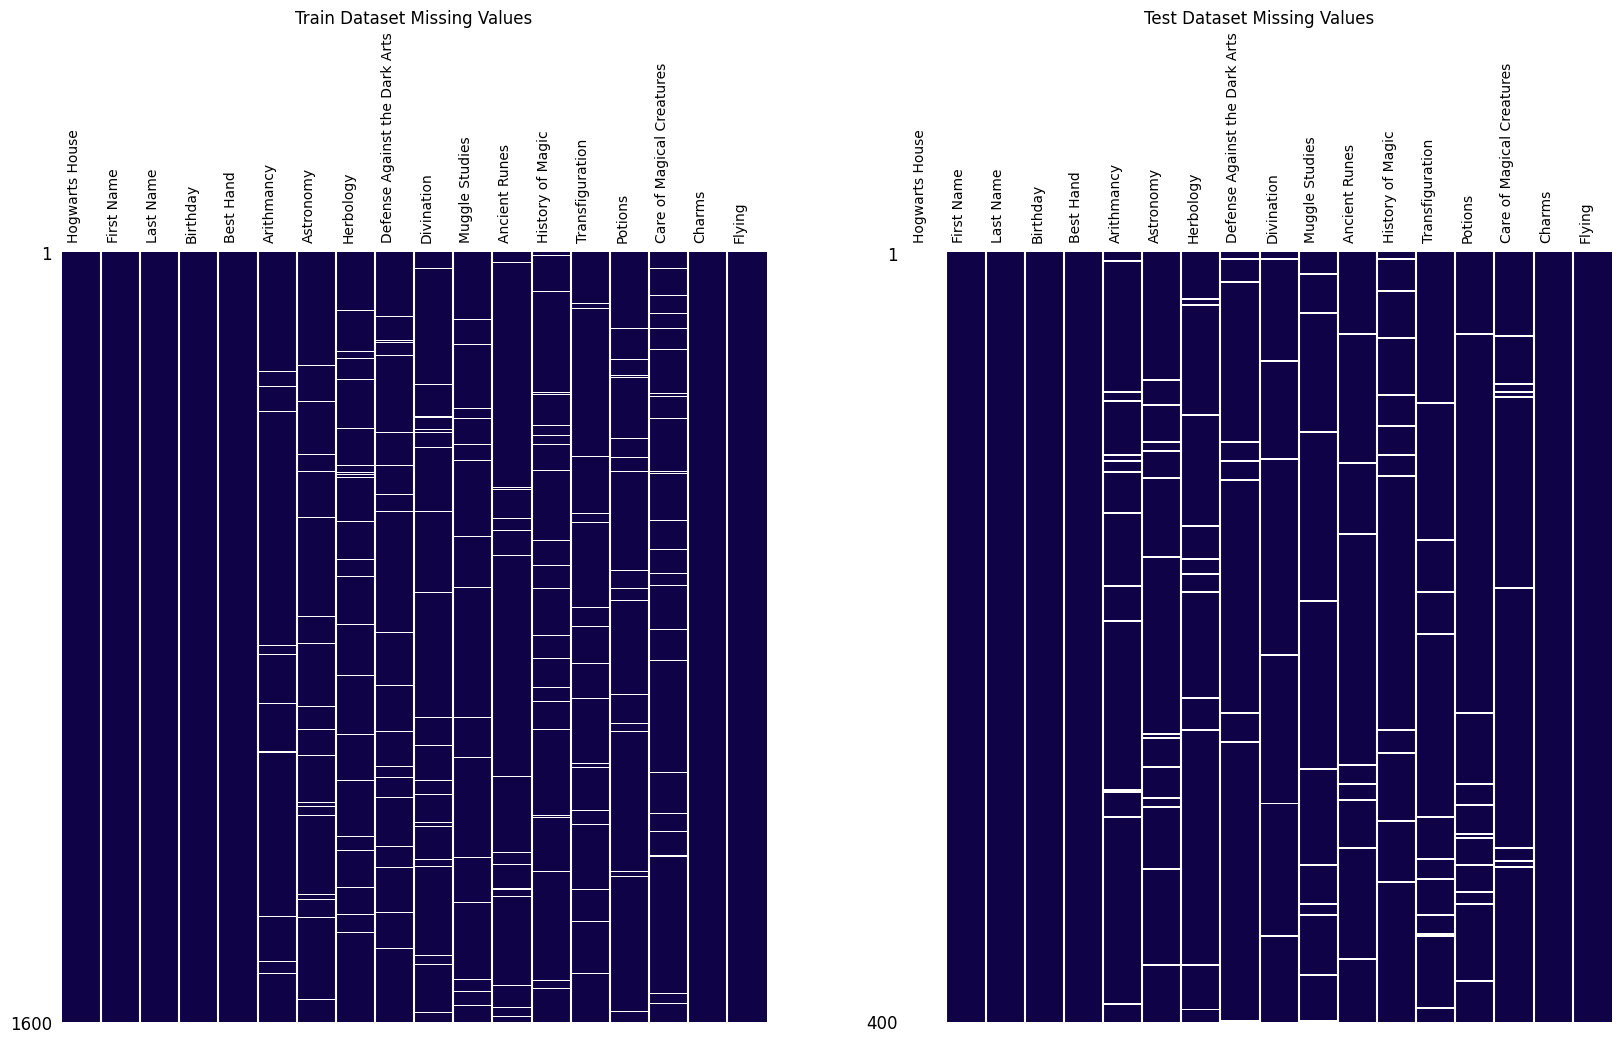

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(20, 10))

# sparkline=False silences a warning, since it can't render on a shared axis anyway
msno.matrix(train_df, color=(16/255, 2/255, 71/255), ax=axes[0], fontsize=10, sparkline=False)
axes[0].set_title("Train Dataset Missing Values", fontsize=12)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=90, ha='right')

msno.matrix(test_df, color=(16/255, 2/255, 71/255), ax=axes[1], fontsize=10, sparkline=False)
axes[1].set_title("Test Dataset Missing Values", fontsize=12)
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=90, ha='right')

plt.show()

In [22]:
# Column groups used throughout the notebook
HOUSE = 'Hogwarts House'
COURSES = ['Arithmancy', 'Astronomy', 'Herbology', 'Defense Against the Dark Arts', 'Divination',
           'Muggle Studies', 'Ancient Runes', 'History of Magic', 'Transfiguration', 'Potions',
           'Care of Magical Creatures', 'Charms', 'Flying']
HOUSES = ['Gryffindor', 'Hufflepuff', 'Ravenclaw', 'Slytherin']
HOUSE_COLORS = {'Gryffindor': '#c24656', 'Hufflepuff': '#e8c547', 'Ravenclaw': '#3b6fd4', 'Slytherin': '#30a14e'}

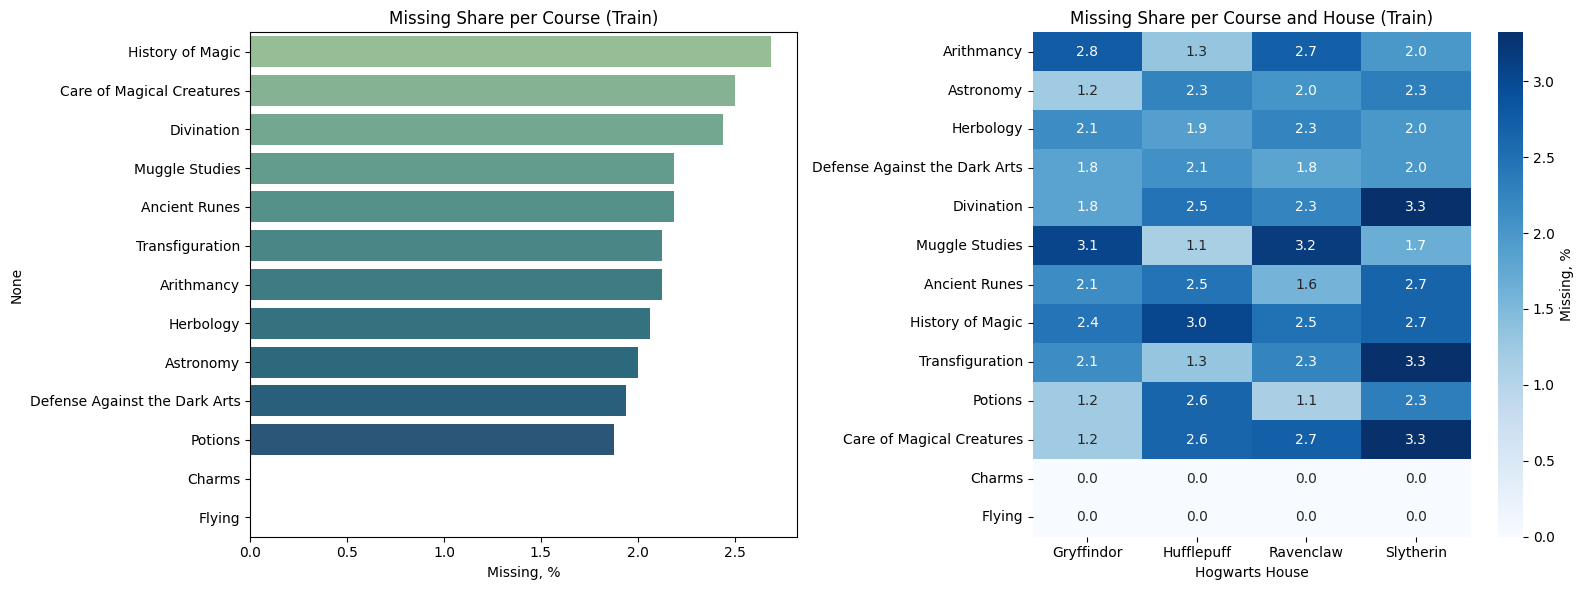

In [23]:
missing_pct = (train_df[COURSES].isna().mean() * 100).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(x=missing_pct.values, y=missing_pct.index, hue=missing_pct.index, palette='crest', legend=False, ax=axes[0])
axes[0].set_title('Missing Share per Course (Train)')
axes[0].set_xlabel('Missing, %')

# Missing share per house: each cell is the % of that house's students without a score for the course
missing_by_house = train_df[COURSES].isna().groupby(train_df[HOUSE]).mean().T * 100
sns.heatmap(missing_by_house, annot=True, fmt='.1f', cmap='Blues', ax=axes[1], cbar_kws={'label': 'Missing, %'})
axes[1].set_title('Missing Share per Course and House (Train)')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

In [24]:
# How many missing course scores does a single student have?
print(train_df[COURSES].isna().sum(axis=1).value_counts().sort_index())

0    1251
1     313
2      35
3       1
Name: count, dtype: int64


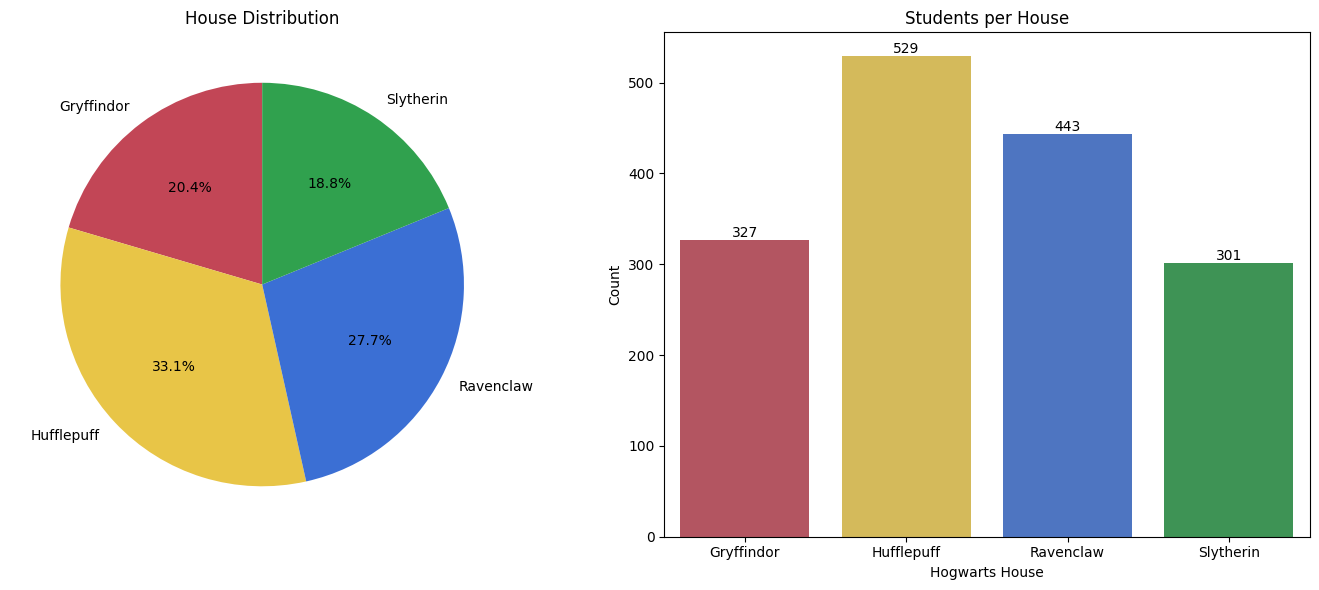

In [25]:
house_counts = train_df[HOUSE].value_counts().reindex(HOUSES)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].pie(house_counts, labels=house_counts.index, autopct='%1.1f%%', startangle=90, colors=[HOUSE_COLORS[h] for h in house_counts.index])
axes[0].set_title('House Distribution')

sns.barplot(x=house_counts.index, y=house_counts.values, hue=house_counts.index, palette=HOUSE_COLORS, legend=False, ax=axes[1])
axes[1].set_title('Students per House')
axes[1].set_ylabel('Count')
for i, v in enumerate(house_counts.values):
    axes[1].text(i, v, str(v), ha='center', va='bottom')

plt.tight_layout()
plt.show()

In [26]:
cols = ['First Name', 'Last Name', 'Birthday', 'Best Hand', HOUSE]

max_len = max(len(col) for col in cols)

for col in cols:
    print(f'{col:<{max_len}}  {train_df[col].nunique()}')

First Name      1215
Last Name       1378
Birthday        1065
Best Hand       2
Hogwarts House  4


In [27]:
print(train_df.duplicated().sum())
print(test_df.duplicated().sum())

# Same person appearing more than once (by full name)?
print(train_df.duplicated(subset=['First Name', 'Last Name']).sum())

0
0
1


In [28]:
train_people = set(zip(train_df['First Name'], train_df['Last Name'], train_df['Birthday']))
test_people = set(zip(test_df['First Name'], test_df['Last Name'], test_df['Birthday']))
print(f"Students appearing in both train and test: {len(train_people & test_people)}")

Students appearing in both train and test: 0


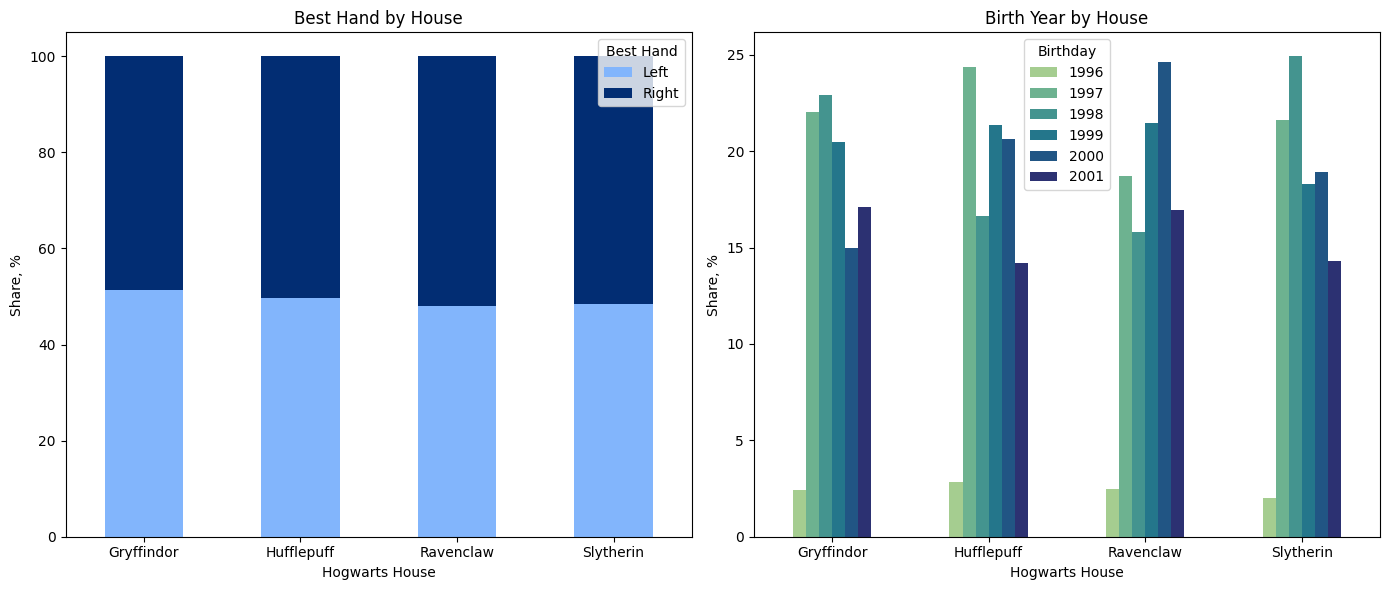

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

hand_share = pd.crosstab(train_df[HOUSE], train_df['Best Hand'], normalize='index').reindex(HOUSES) * 100
hand_share.plot(kind='bar', stacked=True, ax=axes[0], color=['#82B5FC', '#022d73'])
axes[0].set_title('Best Hand by House')
axes[0].set_ylabel('Share, %')
axes[0].tick_params(axis='x', rotation=0)

birth_year = pd.to_datetime(train_df['Birthday']).dt.year
year_share = pd.crosstab(train_df[HOUSE], birth_year, normalize='index').reindex(HOUSES) * 100
year_share.plot(kind='bar', ax=axes[1], colormap='crest')
axes[1].set_title('Birth Year by House')
axes[1].set_ylabel('Share, %')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

In [30]:
scale_df = pd.DataFrame({
    'min': train_df[COURSES].min(),
    'max': train_df[COURSES].max(),
    'mean': train_df[COURSES].mean(),
    'std': train_df[COURSES].std(),
})
scale_df['range'] = scale_df['max'] - scale_df['min']
scale_df.sort_values('range', ascending=False)

,min,max,mean,std,range
Arithmancy,-24370.000000,104956.000000,49634.570243,16679.806036,129326.000000
Muggle Studies,-1086.496835,1092.388611,-224.589915,486.344840,2178.885445
Astronomy,-966.740546,1016.211940,39.797131,520.298268,1982.952486
Ancient Runes,283.869609,745.396220,495.747970,106.285165,461.526611
Flying,-181.470000,279.070000,21.958012,97.631602,460.540000
Transfiguration,906.627320,1098.958201,1030.096946,44.125116,192.330881
Charms,-261.048920,-225.428140,-243.374409,8.783640,35.620780
Herbology,-10.295663,11.612895,1.141020,5.219682,21.908558
History of Magic,-8.858993,11.889713,2.963095,4.425775,20.748706
Defense Against the Dark Arts,-10.162119,9.667405,-0.387863,5.212794,19.829525


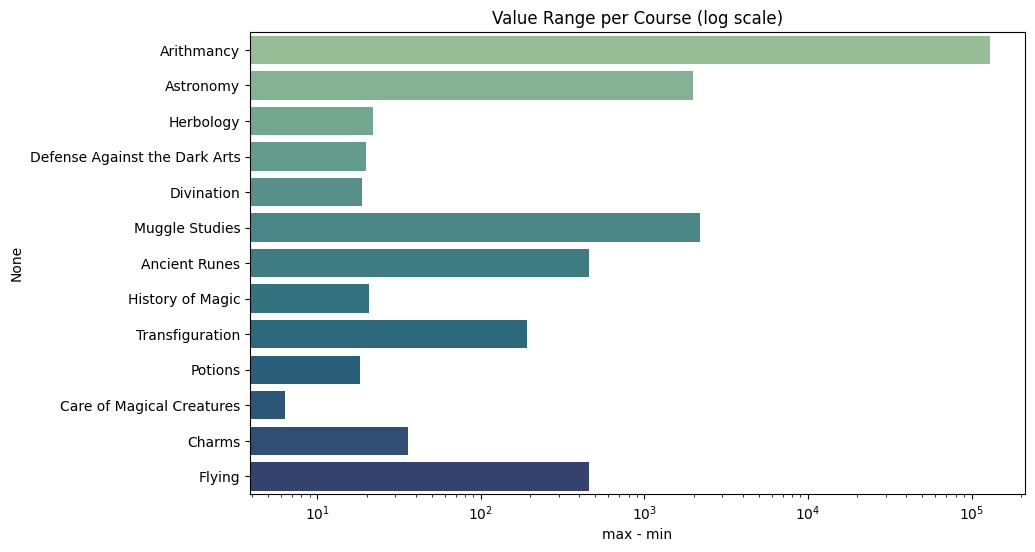

In [31]:
plt.figure(figsize=(10, 6))
sns.barplot(x=scale_df['range'], y=scale_df.index, hue=scale_df.index, palette='crest', legend=False)
plt.xscale('log')
plt.title('Value Range per Course (log scale)')
plt.xlabel('max - min')
plt.show()

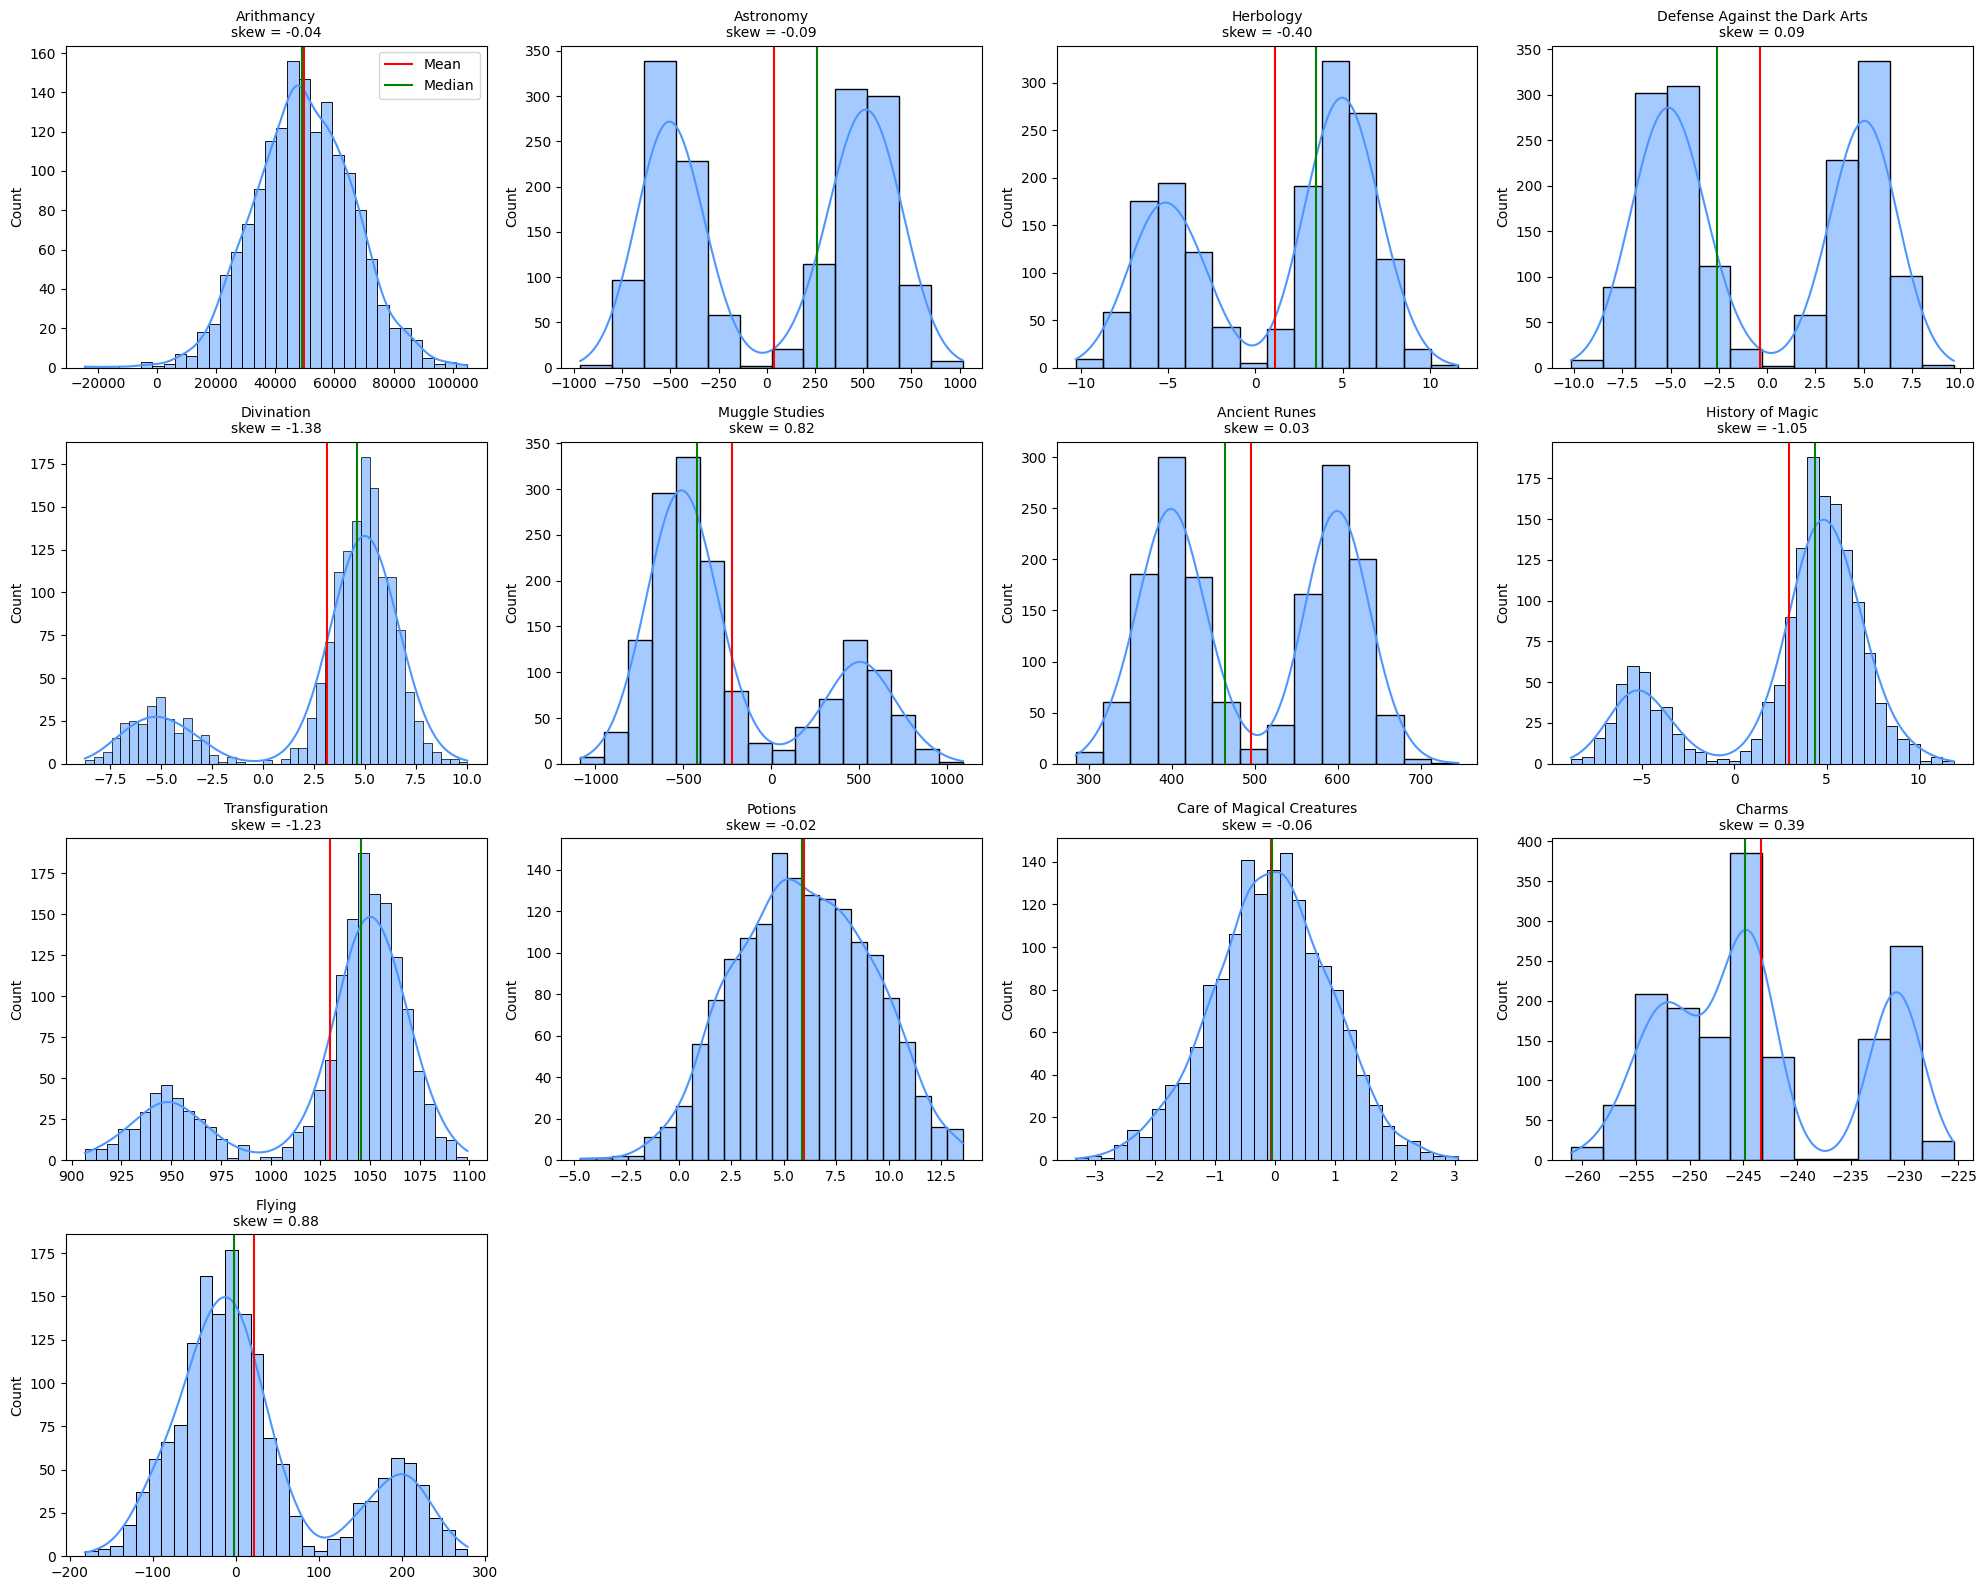

In [32]:
fig, axes = plt.subplots(4, 4, figsize=(20, 16))
axes = axes.ravel()

skew_values = {}
for ax, course in zip(axes, COURSES):
    values = train_df[course].dropna()
    skew_values[course] = skew(values)
    sns.histplot(values, kde=True, color='#4D96FF', ax=ax)
    ax.axvline(values.mean(), color='red', linewidth=1.5, label='Mean')
    ax.axvline(values.median(), color='green', linewidth=1.5, label='Median')
    ax.set_title(f'{course}\nskew = {skew_values[course]:.2f}', fontsize=10)
    ax.set_xlabel('')

for ax in axes[len(COURSES):]:
    ax.axis('off')
axes[0].legend()

plt.tight_layout()
plt.show()

In [33]:
pd.Series(skew_values).sort_values().round(3)

Divination                      -1.379
Transfiguration                 -1.229
History of Magic                -1.047
Herbology                       -0.398
Astronomy                       -0.095
Care of Magical Creatures       -0.062
Arithmancy                      -0.042
Potions                         -0.024
Ancient Runes                    0.034
Defense Against the Dark Arts    0.093
Charms                           0.390
Muggle Studies                   0.825
Flying                           0.883
dtype: float64

In [34]:
rows = []
for course in COURSES:
    s = train_df[course].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    n_out = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()
    rows.append((course, n_out, n_out / len(s) * 100))

outliers_df = pd.DataFrame(rows, columns=['course', 'outliers', 'share, %']).set_index('course')
outliers_df.sort_values('outliers', ascending=False).round(2)

,outliers,"share, %"
course,,
Transfiguration,303,19.35
History of Magic,292,18.75
Divination,287,18.39
Flying,183,11.44
Care of Magical Creatures,15,0.96
Arithmancy,13,0.83
Potions,2,0.13
Astronomy,0,0.00
Herbology,0,0.00


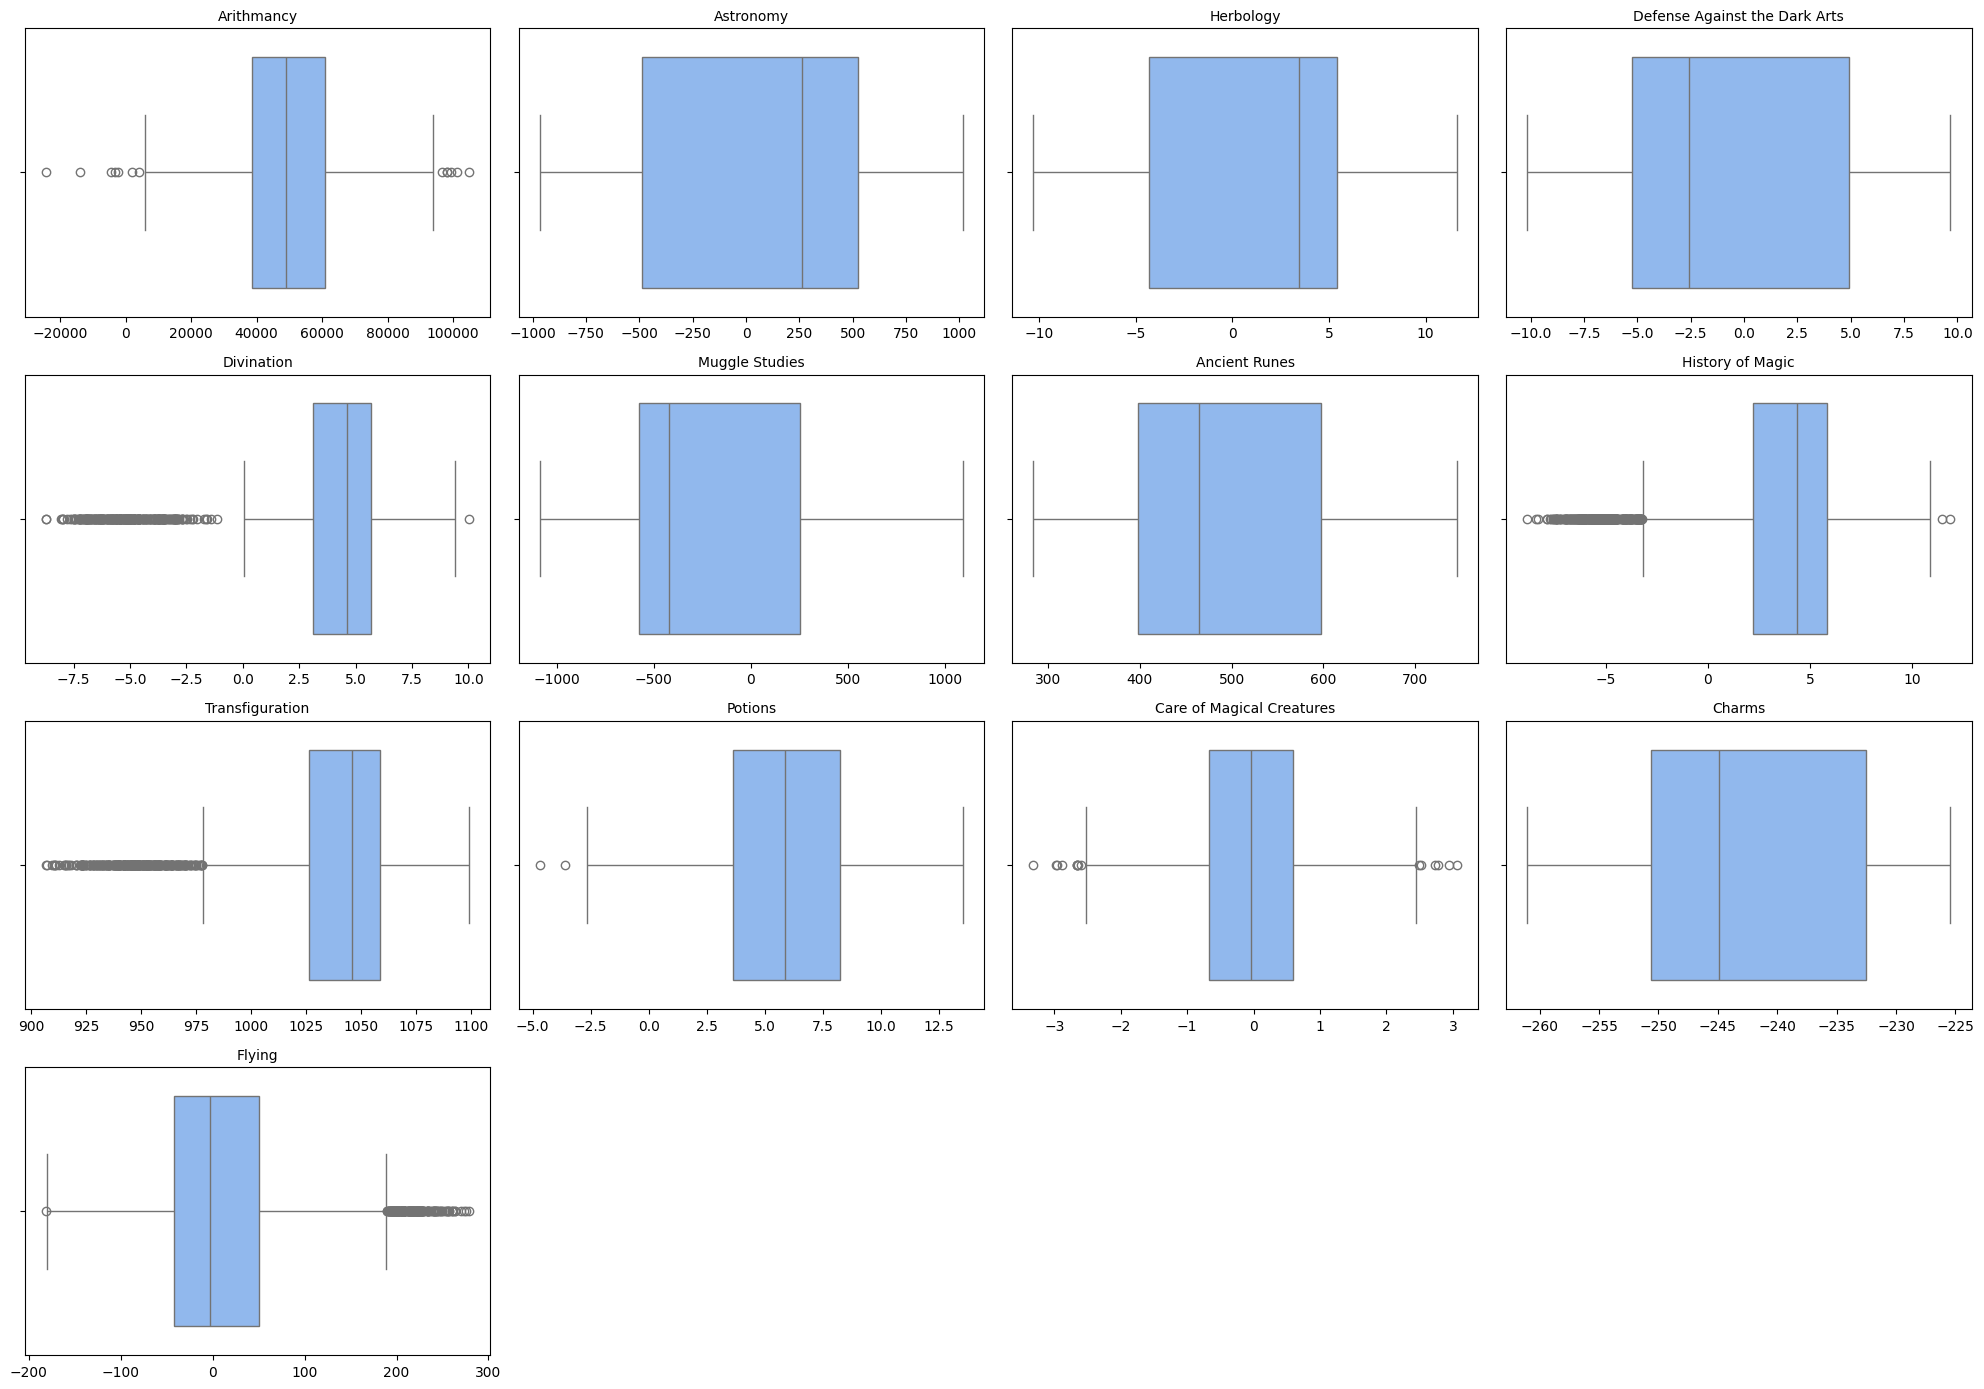

In [35]:
fig, axes = plt.subplots(4, 4, figsize=(20, 14))
axes = axes.ravel()

for ax, course in zip(axes, COURSES):
    sns.boxplot(x=train_df[course], color='#82B5FC', ax=ax)
    ax.set_title(course, fontsize=10)
    ax.set_xlabel('')

for ax in axes[len(COURSES):]:
    ax.axis('off')

plt.tight_layout()
plt.show()

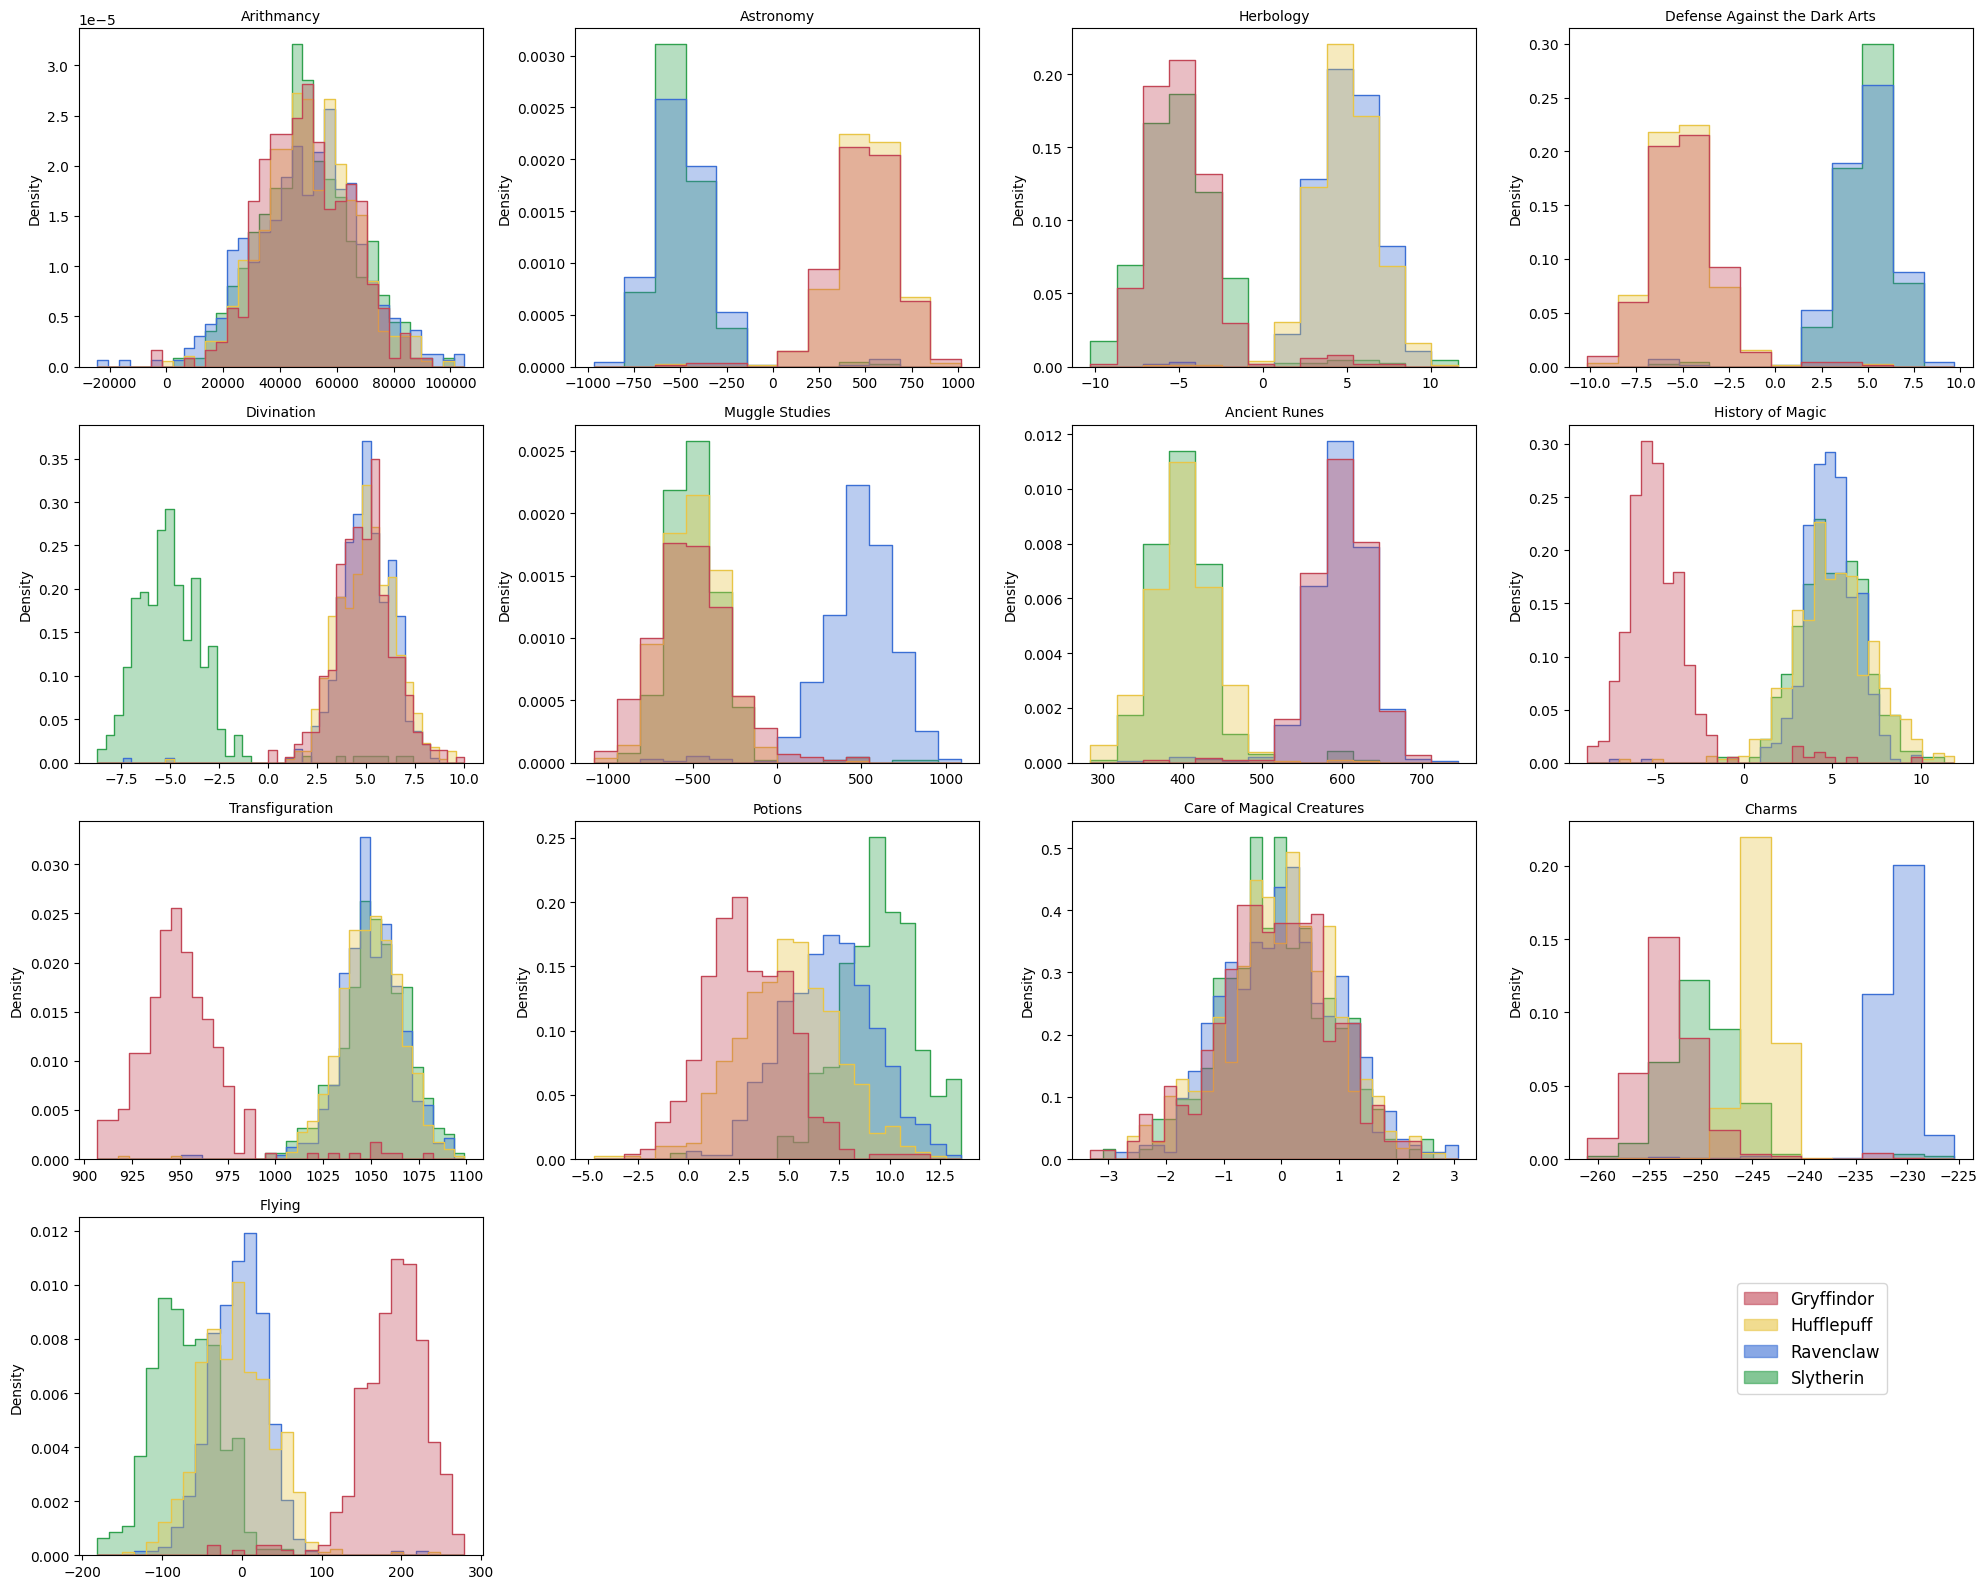

In [36]:
fig, axes = plt.subplots(4, 4, figsize=(20, 16))
axes = axes.ravel()

for ax, course in zip(axes, COURSES):
    sns.histplot(data=train_df, x=course, hue=HOUSE, hue_order=HOUSES, palette=HOUSE_COLORS,
                 element='step', stat='density', common_norm=False, fill=True, alpha=0.35, ax=ax, legend=False)
    ax.set_title(course, fontsize=10)
    ax.set_xlabel('')

for ax in axes[len(COURSES):]:
    ax.axis('off')

handles = [plt.Rectangle((0, 0), 1, 1, color=HOUSE_COLORS[h], alpha=0.6) for h in HOUSES]
fig.legend(handles, HOUSES, loc='lower right', bbox_to_anchor=(0.95, 0.12), fontsize=12)

plt.tight_layout()
plt.show()

In [37]:
# One-way ANOVA per course: how strongly do the house means differ?
anova_rows = []
for course in COURSES:
    groups = [train_df.loc[train_df[HOUSE] == h, course].dropna() for h in HOUSES]
    f_stat, p_value = f_oneway(*groups)
    anova_rows.append((course, f_stat, p_value))

anova_df = pd.DataFrame(anova_rows, columns=['course', 'F', 'p_value']).set_index('course').sort_values('F')
anova_df

,F,p_value
course,,
Arithmancy,0.377933,7.689337e-01
Care of Magical Creatures,1.572826,1.940722e-01
Potions,491.070320,7.291104e-225
History of Magic,2025.292759,0.000000e+00
Muggle Studies,2277.625771,0.000000e+00
Flying,2356.528026,0.000000e+00
Transfiguration,2425.801047,0.000000e+00
Herbology,2577.281659,0.000000e+00
Divination,2792.179132,0.000000e+00


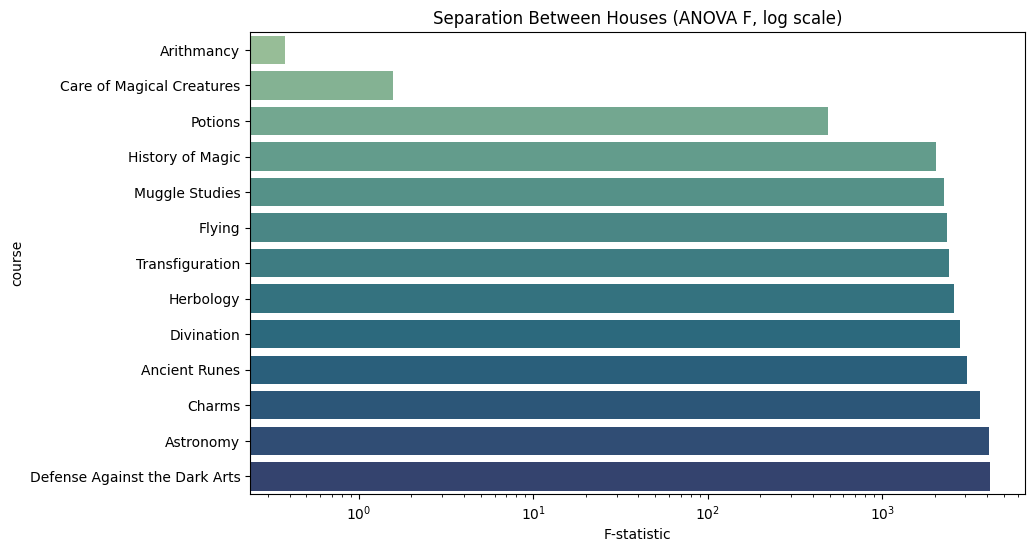

In [38]:
plt.figure(figsize=(10, 6))
sns.barplot(x=anova_df['F'], y=anova_df.index, hue=anova_df.index, palette='crest', legend=False)
plt.xscale('log')
plt.title('Separation Between Houses (ANOVA F, log scale)')
plt.xlabel('F-statistic')
plt.show()

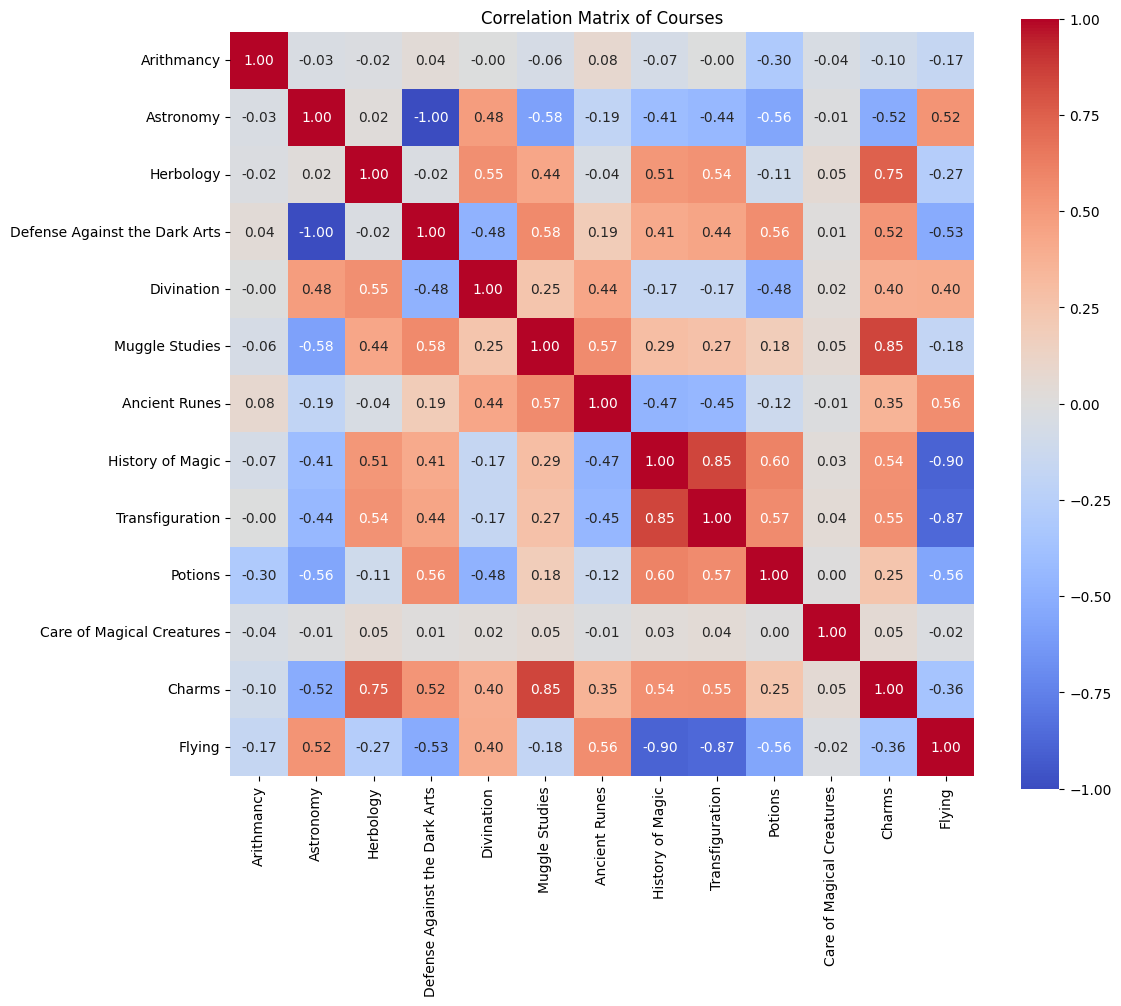

In [39]:
corr = train_df[COURSES].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, square=True)
plt.title('Correlation Matrix of Courses')
plt.show()

In [42]:
# The most strongly correlated pairs (absolute value), each pair listed once
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(5)

Astronomy         Defense Against the Dark Arts   -1.000000
History of Magic  Flying                          -0.896283
Transfiguration   Flying                          -0.873673
History of Magic  Transfiguration                  0.849203
Muggle Studies    Charms                           0.847607
dtype: float64

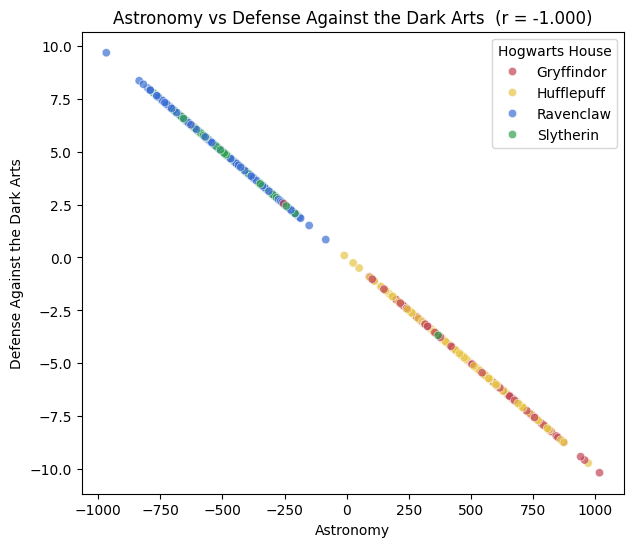

In [43]:
# Scatter plot of the most correlated pair
top_a, top_b = pairs.abs().idxmax()

plt.figure(figsize=(7, 6))
sns.scatterplot(data=train_df, x=top_a, y=top_b, hue=HOUSE, hue_order=HOUSES, palette=HOUSE_COLORS, alpha=0.7)
plt.title(f'{top_a} vs {top_b}  (r = {corr.loc[top_a, top_b]:.3f})')
plt.show()

['Astronomy', 'Charms', 'Ancient Runes', 'Divination', 'Herbology', 'Transfiguration']


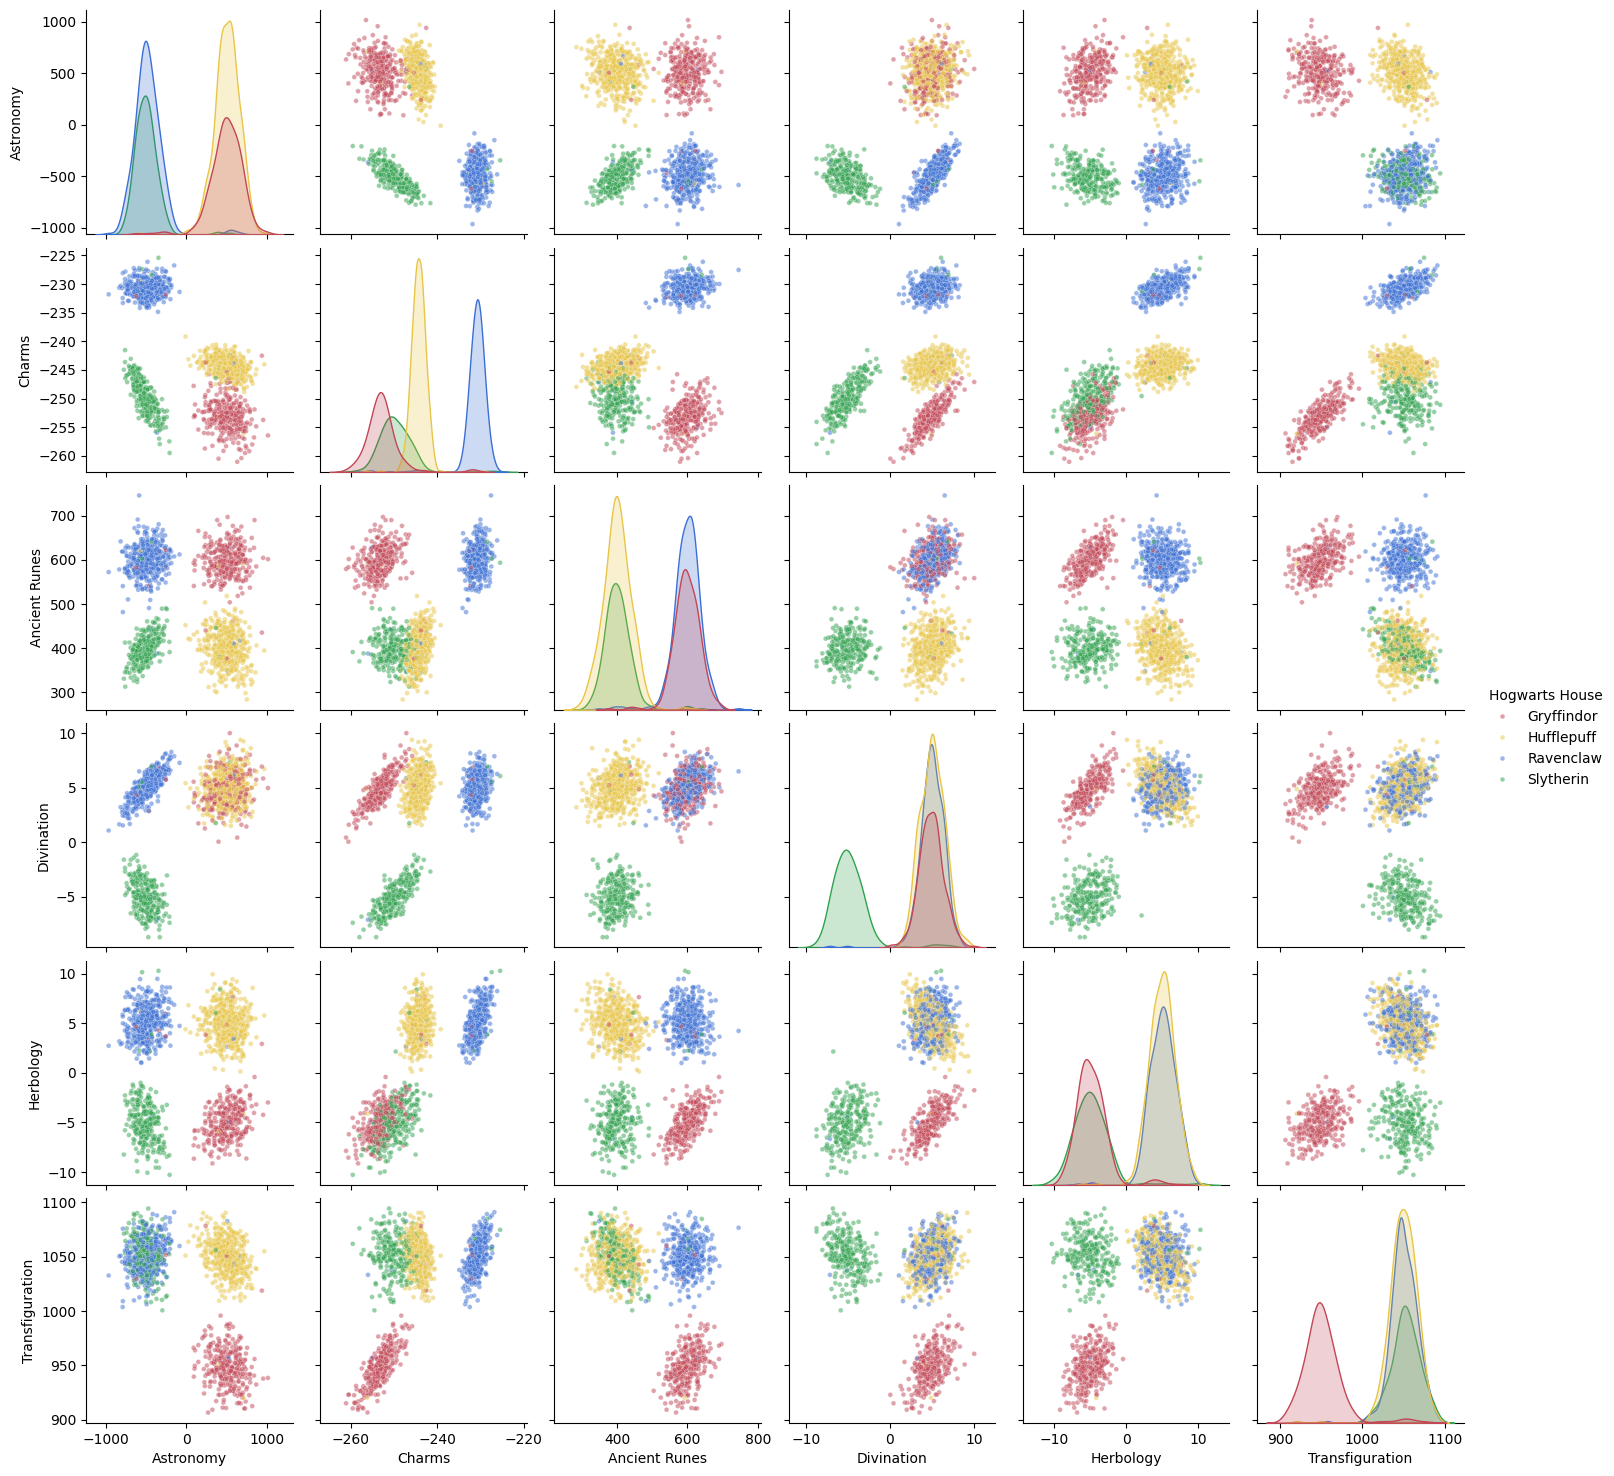

In [44]:
# Candidate features: top courses by ANOVA F, dropping the redundant Astronomy / DADA twin
candidates = [c for c in anova_df.sort_values('F', ascending=False).index if c != 'Defense Against the Dark Arts'][:6]
print(candidates)

sns.pairplot(train_df[candidates + [HOUSE]].dropna(), hue=HOUSE, hue_order=HOUSES, palette=HOUSE_COLORS,
             diag_kind='kde', plot_kws={'alpha': 0.5, 's': 12})
plt.show()

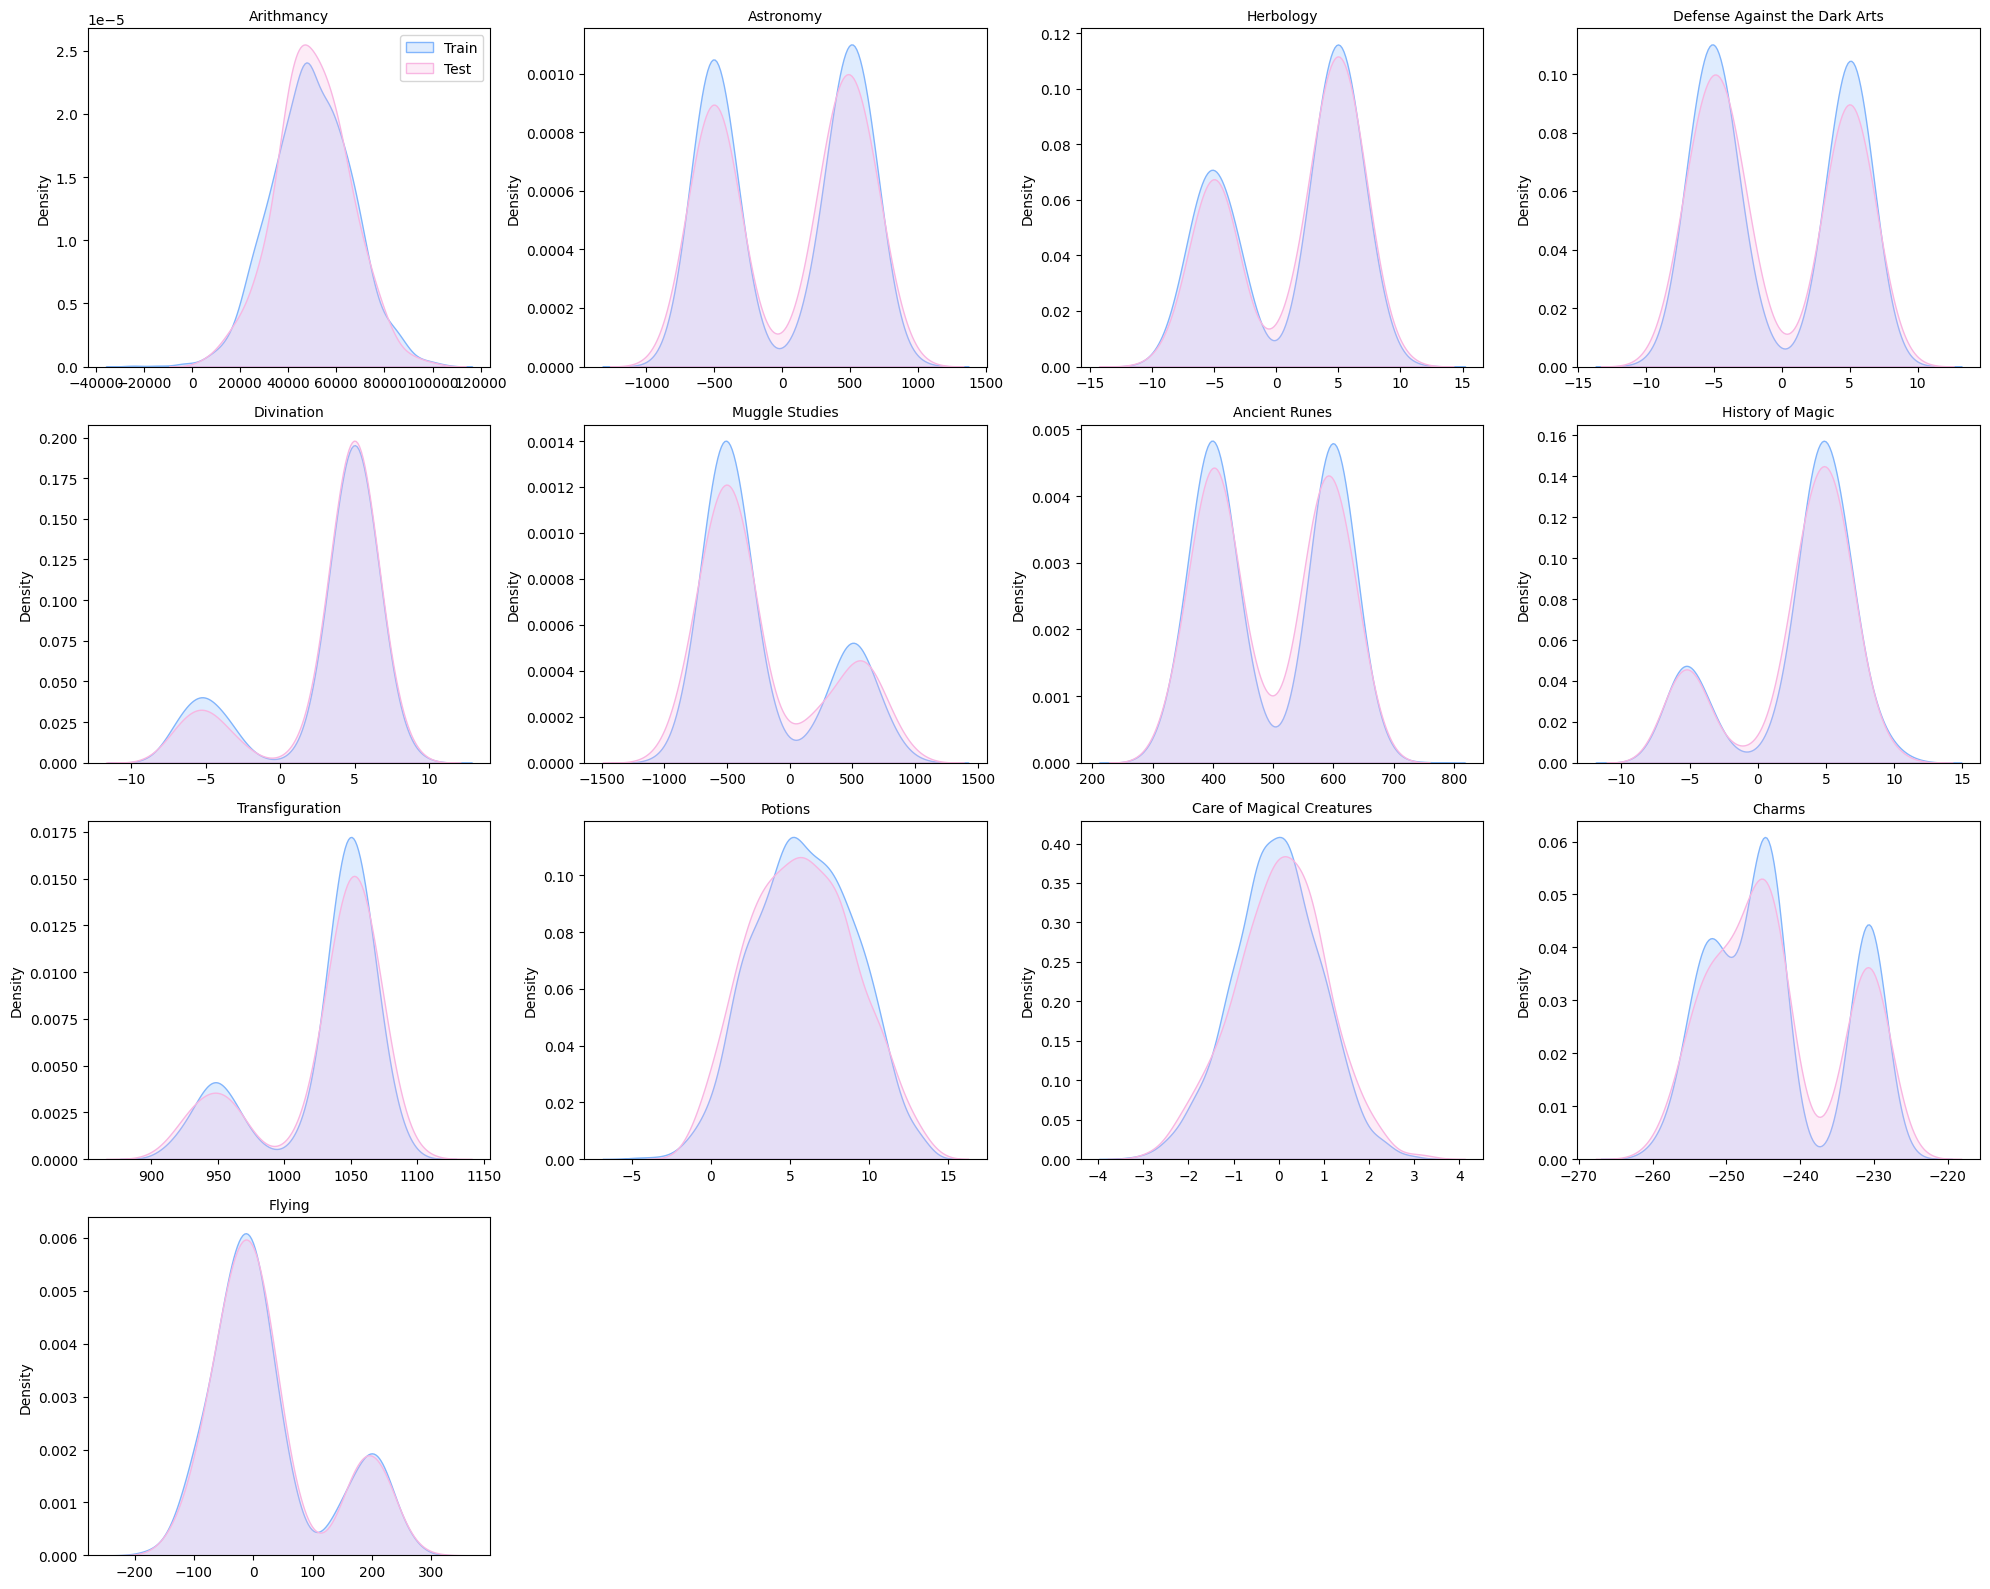

In [45]:
fig, axes = plt.subplots(4, 4, figsize=(20, 16))
axes = axes.ravel()

for ax, course in zip(axes, COURSES):
    sns.kdeplot(train_df[course].dropna(), ax=ax, color='#82B5FC', label='Train', fill=True)
    sns.kdeplot(test_df[course].dropna(), ax=ax, color='#F8B6E2', label='Test', fill=True)
    ax.set_title(course, fontsize=10)
    ax.set_xlabel('')

for ax in axes[len(COURSES):]:
    ax.axis('off')
axes[0].legend()

plt.tight_layout()
plt.show()

In [46]:
ks_rows = []
for course in COURSES:
    stat, p = ks_2samp(train_df[course].dropna(), test_df[course].dropna())
    ks_rows.append((course, stat, p))

pd.DataFrame(ks_rows, columns=['course', 'KS statistic', 'p_value']).set_index('course').round(4)

,KS statistic,p_value
course,,
Arithmancy,0.0608,0.1926
Astronomy,0.0365,0.7859
Herbology,0.0399,0.6850
Defense Against the Dark Arts,0.0336,0.8562
Divination,0.0548,0.2887
Muggle Studies,0.0344,0.8383
Ancient Runes,0.0475,0.4610
History of Magic,0.0426,0.6063
Transfiguration,0.0556,0.2782
